# 14 · Comprehensive continuous PSS regression

An exploratory development benchmark. All displayed tables/figures are aggregates or synthetic examples. The final test remains sealed. No raw sensor processing is repeated.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
REPORT=ROOT/'reports/comprehensive_regression/4e769e522b239f43'
def load(n): return json.loads((REPORT/(n+'.json')).read_text())
def table(n,columns=None,limit=25):
    f=pd.DataFrame(load(n)); display((f[columns] if columns else f).head(limit))
def figure(n): display(Image(filename=str(REPORT/'figures'/n)))

## 1 · Outcome and accounting

The unchanged three-item composite requires all valid items. All 3,706 responses remain accounted for; 3,689 valid-score/context responses enter matched main models. The 3–4 / 5–9 / 10–15 bands are evaluation strata, not new targets.

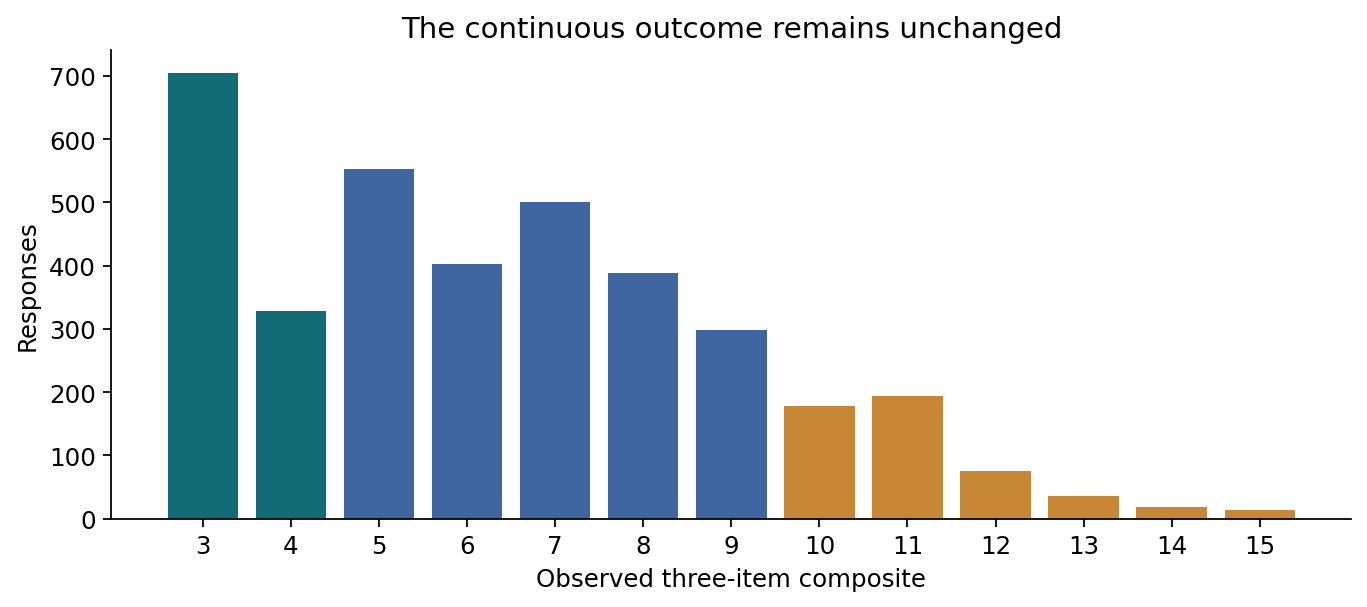

,band_counts,cohort,included,participants,responses,score_mean,score_median,score_sd,scores_available,survey
0,"{'10–15': 515, '3–4': 1033, '5–9': 2141}",all_valid,True,125,3689,6.406885,6.0,2.695515,3689,All
1,"{'10–15': 116, '3–4': 274, '5–9': 542}",all_valid,True,124,932,6.281116,6.0,2.673084,932,Endday
2,"{'10–15': 242, '3–4': 532, '5–9': 1052}",all_valid,True,125,1826,6.343921,6.0,2.691643,1826,Midday
3,"{'10–15': 157, '3–4': 227, '5–9': 547}",all_valid,True,125,931,6.656284,7.0,2.712379,931,Morning
4,"{'10–15': 0, '3–4': 0, '5–9': 0}",all_valid,False,14,17,NaN,NaN,NaN,0,All
5,"{'10–15': 0, '3–4': 0, '5–9': 0}",all_valid,False,2,2,NaN,NaN,NaN,0,Endday
6,"{'10–15': 0, '3–4': 0, '5–9': 0}",all_valid,False,11,12,NaN,NaN,NaN,0,Midday
7,"{'10–15': 0, '3–4': 0, '5–9': 0}",all_valid,False,3,3,NaN,NaN,NaN,0,Morning
8,"{'10–15': 163, '3–4': 384, '5–9': 808}",complete60,True,113,1355,6.267897,6.0,2.543238,1355,All
9,"{'10–15': 38, '3–4': 103, '5–9': 232}",complete60,True,97,373,6.222520,6.0,2.469454,373,Endday


In [2]:
figure('01_outcome.png')
table('cohort_composition')

## 2 · Reused features and a synthetic example

438 supported summaries across eight windows; 240 provisional PulseOx columns only in a separate sensitivity. Example: minute start 09:22 → cutoff 09:21 → 60-minute interval [08:21,09:21). Items 4,2,3 give 11. Prediction 7 has MAE contribution 4 and residual −4. No current answer reaches the predictors.

In [3]:
display(pd.DataFrame([{'synthetic_nervous':4,'synthetic_cope':2,'synthetic_control':3,'composite':4+(6-2)+(6-3),'prediction':7,'absolute_error':4,'signed_residual':-4}]))
table('feature_availability',limit=28)

,synthetic_nervous,synthetic_cope,synthetic_control,composite,prediction,absolute_error,signed_residual
0,4,2,3,11,7,4,-4


,block,candidate_columns,complete_responses,median_observed_columns,no_observed_columns,responses,score_band
0,original60,5,1363,0.0,1952,3706,All
1,original60,5,384,0.0,551,1033,3–4
2,original60,5,808,0.0,1097,2141,5–9
3,original60,5,163,0.0,296,515,10–15
4,hr60,30,1316,0.0,1981,3706,All
5,hr60,30,349,0.0,565,1033,3–4
6,hr60,30,796,0.0,1107,2141,5–9
7,hr60,30,163,0.0,301,515,10–15
8,hr_all,240,593,117.0,242,3706,All
9,hr_all,240,150,92.0,74,1033,3–4


## 3 · Nested evaluation

Five unchanged participant folds; three grouped inner folds. Training-only imputation, scaling, encoding and selection. Inner MAE selects settings. No row-level early stopping, target imputation, clipping or model expansion based on held-out results. Boosting families compare both absolute and squared-error losses.

In [4]:
table('settings',['view','family','fold','setting','inner_mae','selected_features','nonconverged_candidates'])
table('failures')

,view,family,fold,setting,inner_mae,selected_features,nonconverged_candidates
0,context,elastic,0,{'alpha': 0.01},2.216168,5,0
1,context,elastic,1,{'alpha': 0.01},2.220137,5,0
2,context,elastic,2,{'alpha': 0.01},2.310734,5,0
3,context,elastic,3,{'alpha': 0.01},2.199549,5,0
4,context,elastic,4,{'alpha': 0.01},2.269965,5,0
5,context,hgb,0,"{'loss': 'absolute_error', 'max_depth': 2, 'ma...",2.197423,5,0
6,context,hgb,1,"{'loss': 'absolute_error', 'max_depth': 1, 'ma...",2.187591,5,0
7,context,hgb,2,"{'loss': 'absolute_error', 'max_depth': 1, 'ma...",2.269335,5,0
8,context,hgb,3,"{'loss': 'absolute_error', 'max_depth': 1, 'ma...",2.173337,5,0
9,context,hgb,4,"{'loss': 'absolute_error', 'max_depth': 1, 'ma...",2.252827,5,0


""


## 4 · Matched model and feature comparisons

Read MAE beside RMSE, R², correlation and prediction spread. The median dummy must be fitted on the matching training cohort.

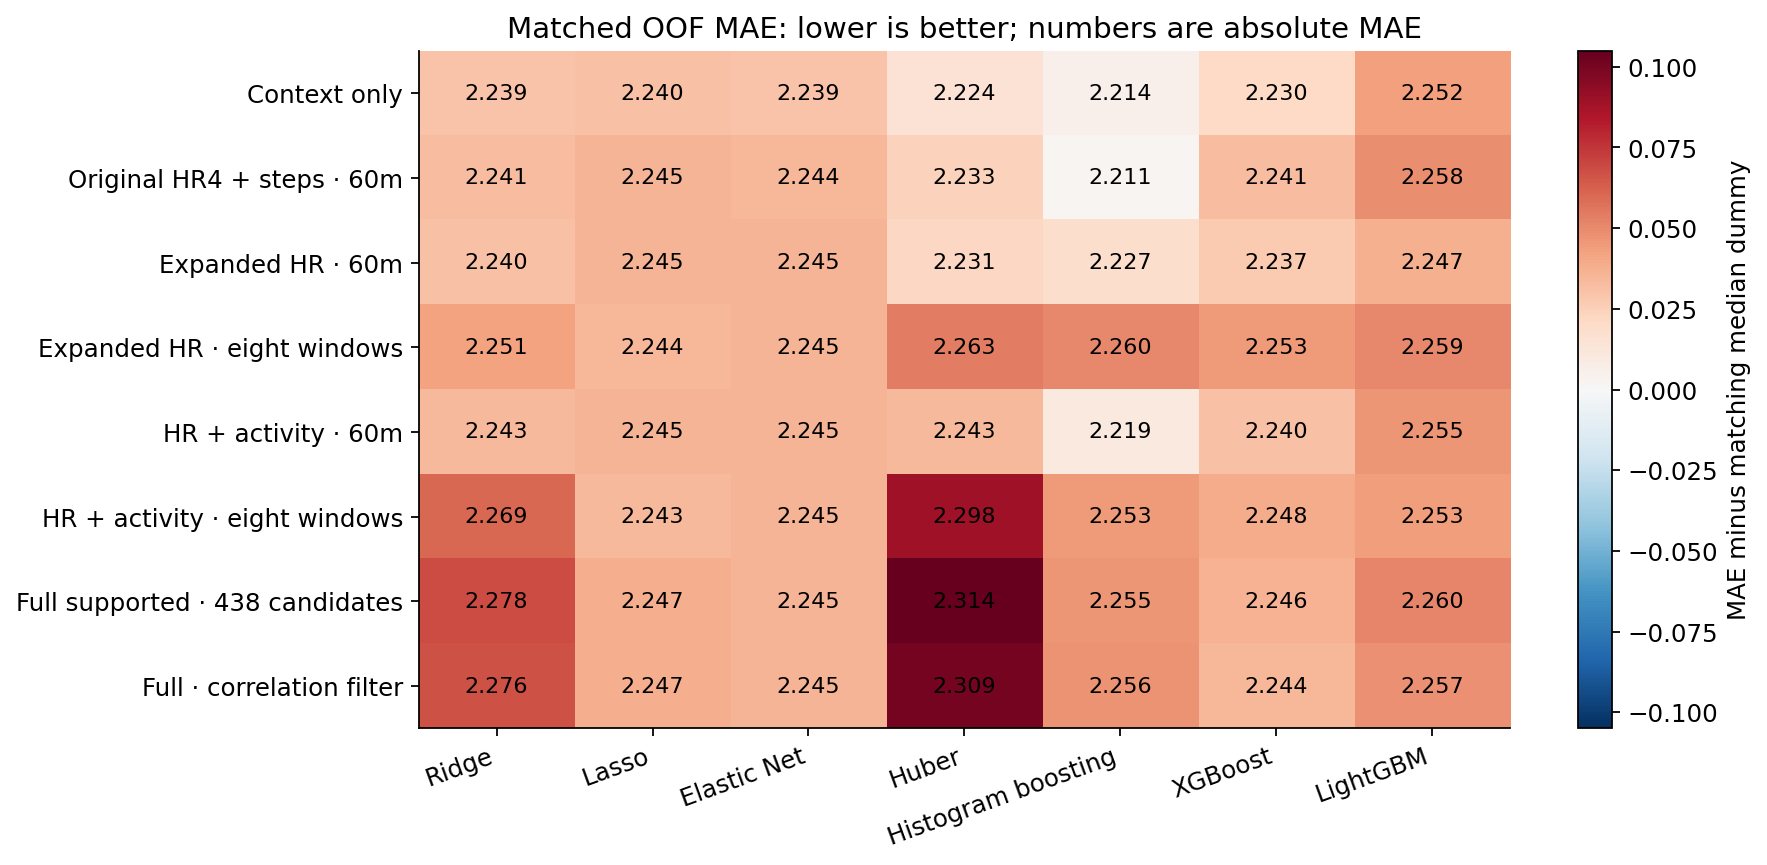

,family,mae,mae_low,mae_high,rmse,r2,spearman,prediction_sd
7,dummy_mean,2.244591,2.116164,2.368073,2.700385,-0.003889,-0.095459,0.055830
8,dummy_median,2.209000,2.073029,2.344534,2.725690,-0.022792,NaN,0.000000
9,elastic,2.244591,2.116164,2.368073,2.700385,-0.003889,-0.095459,0.055830
10,hgb,2.255455,2.119035,2.393373,2.759637,-0.048427,-0.052548,0.422577
11,huber,2.313957,2.187598,2.439601,2.872877,-0.136235,0.018947,1.071943
12,lasso,2.247417,2.119947,2.373837,2.703673,-0.006335,-0.071899,0.219749
13,lgbm,2.260206,2.131475,2.389986,2.742082,-0.035131,0.011729,0.568094
14,ridge,2.277865,2.155725,2.400207,2.774037,-0.059398,0.022943,0.760829
15,xgb,2.245631,2.114392,2.373064,2.718036,-0.017056,0.001065,0.441455


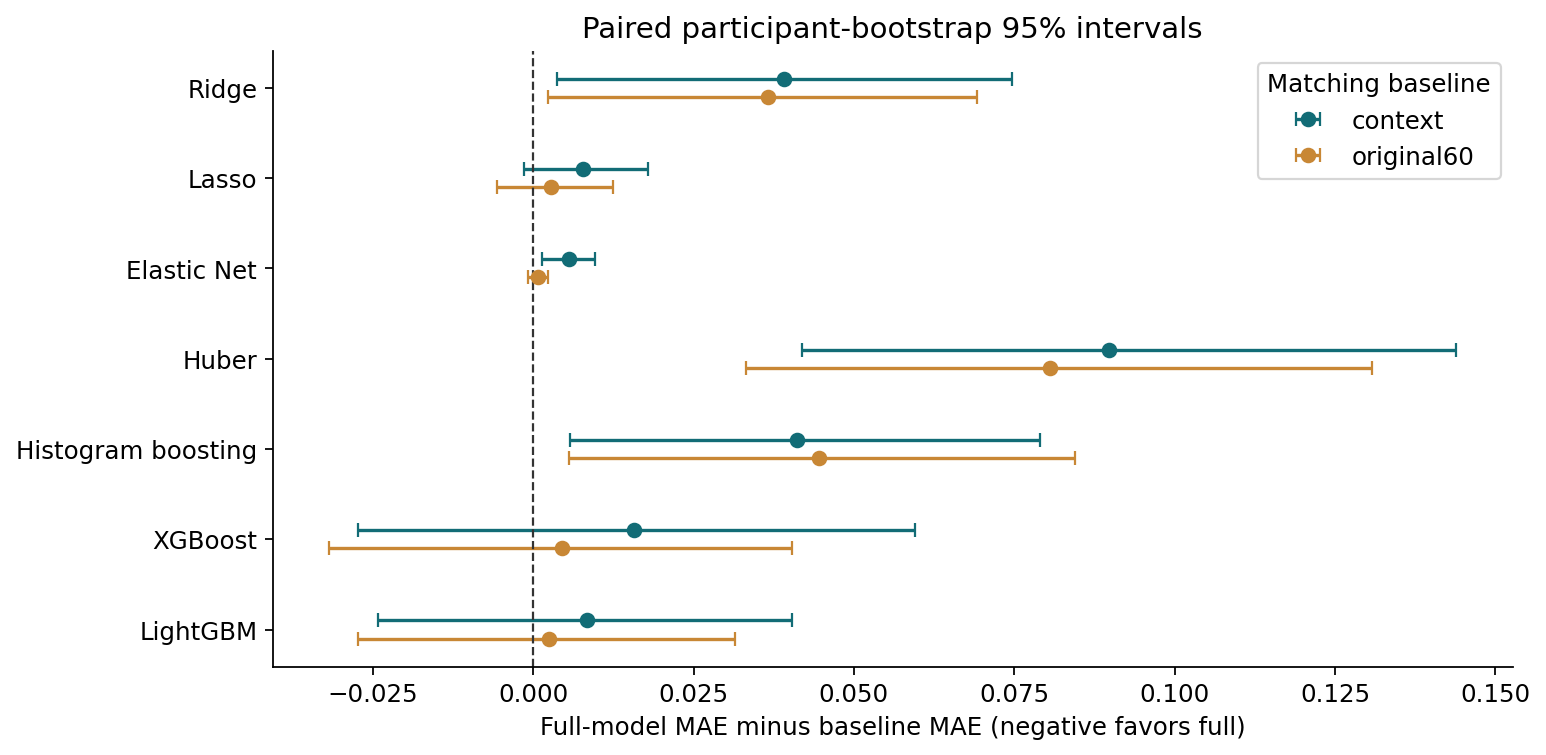

In [5]:
figure('02_model_features.png')
f=pd.DataFrame(load('metrics'))
display(f[f.cohort.eq('all_valid') & (f['view'].eq('full') | f.family.str.startswith('dummy_'))][['family','mae','mae_low','mae_high','rmse','r2','spearman','prediction_sd']])
figure('03_paired.png')

## 5 · Higher outcomes and collapsed predictions

The ideal line is actual = predicted. Density cells with fewer than five responses are hidden; all observations remain in metrics. Display ranges do not clip model predictions. Negative residuals indicate underprediction.

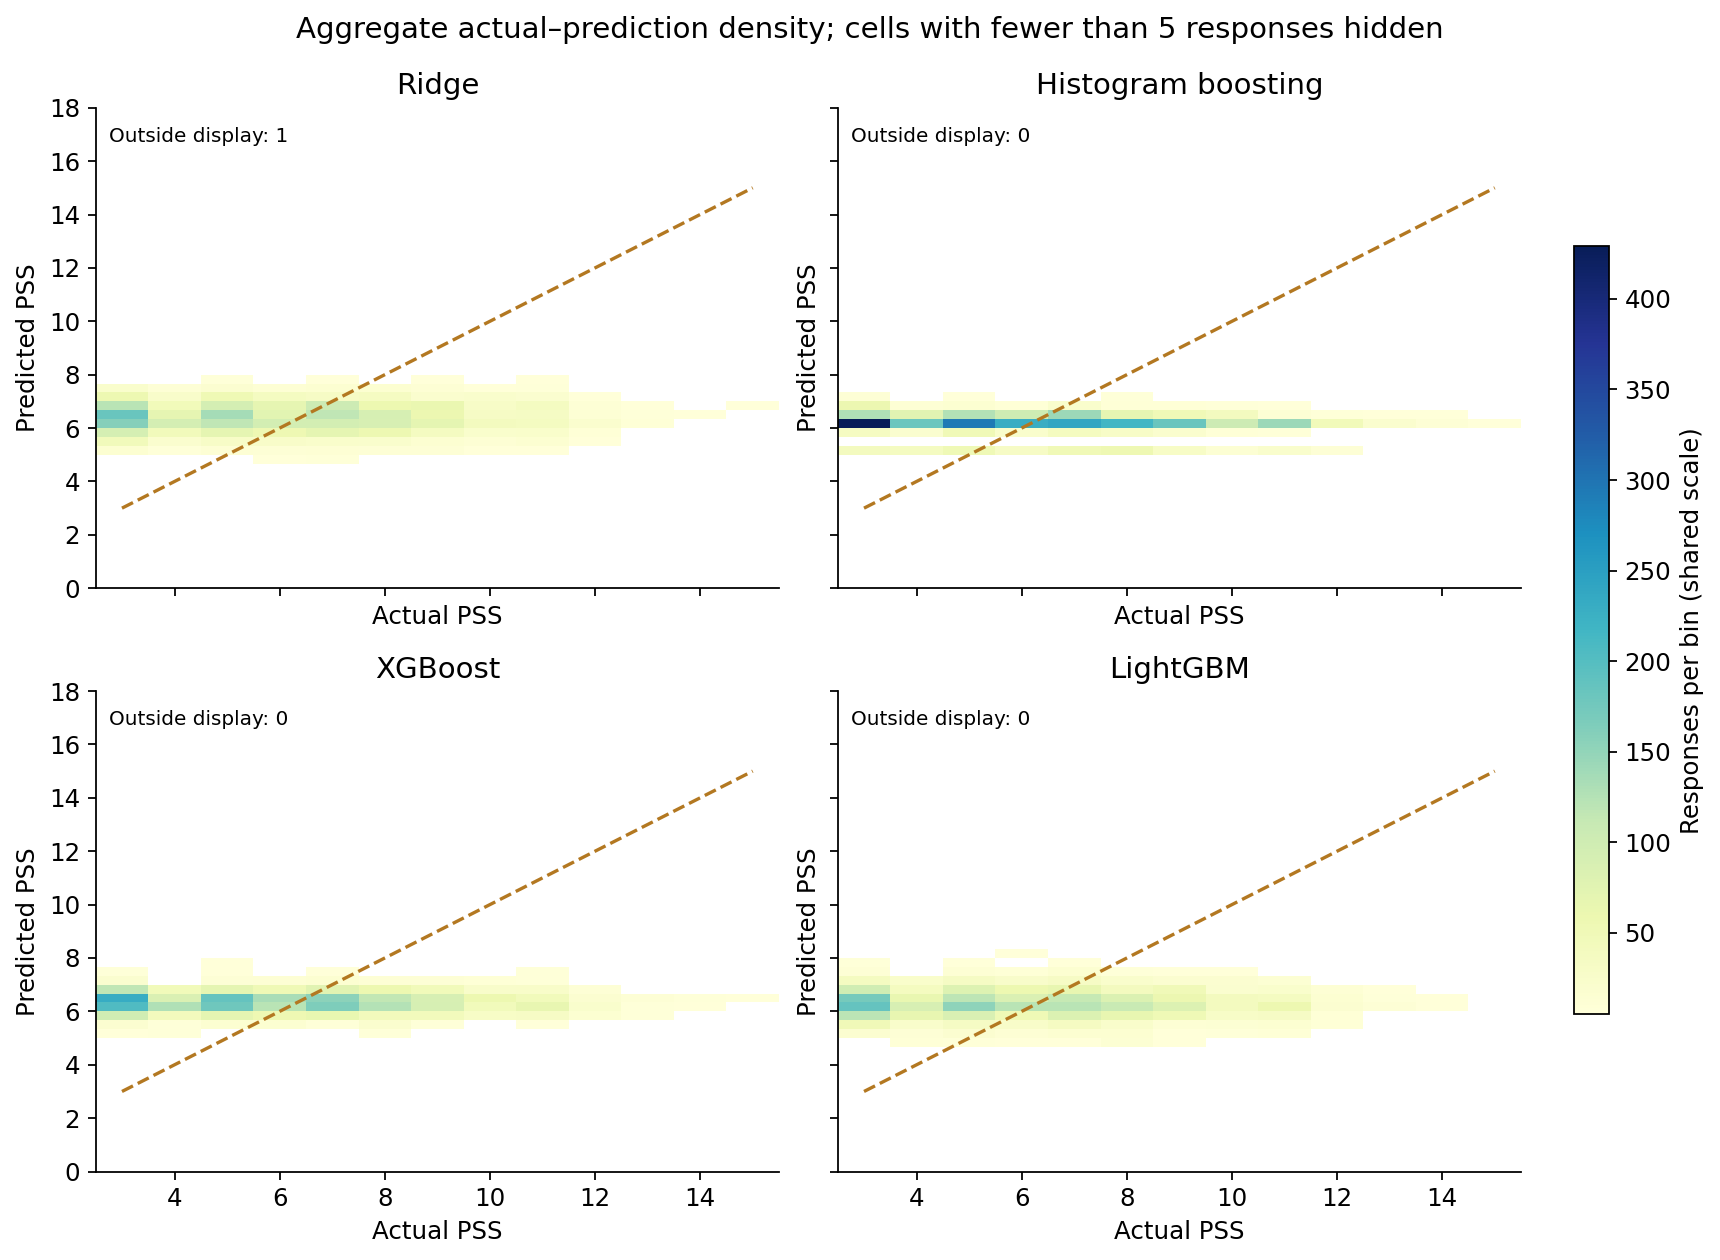

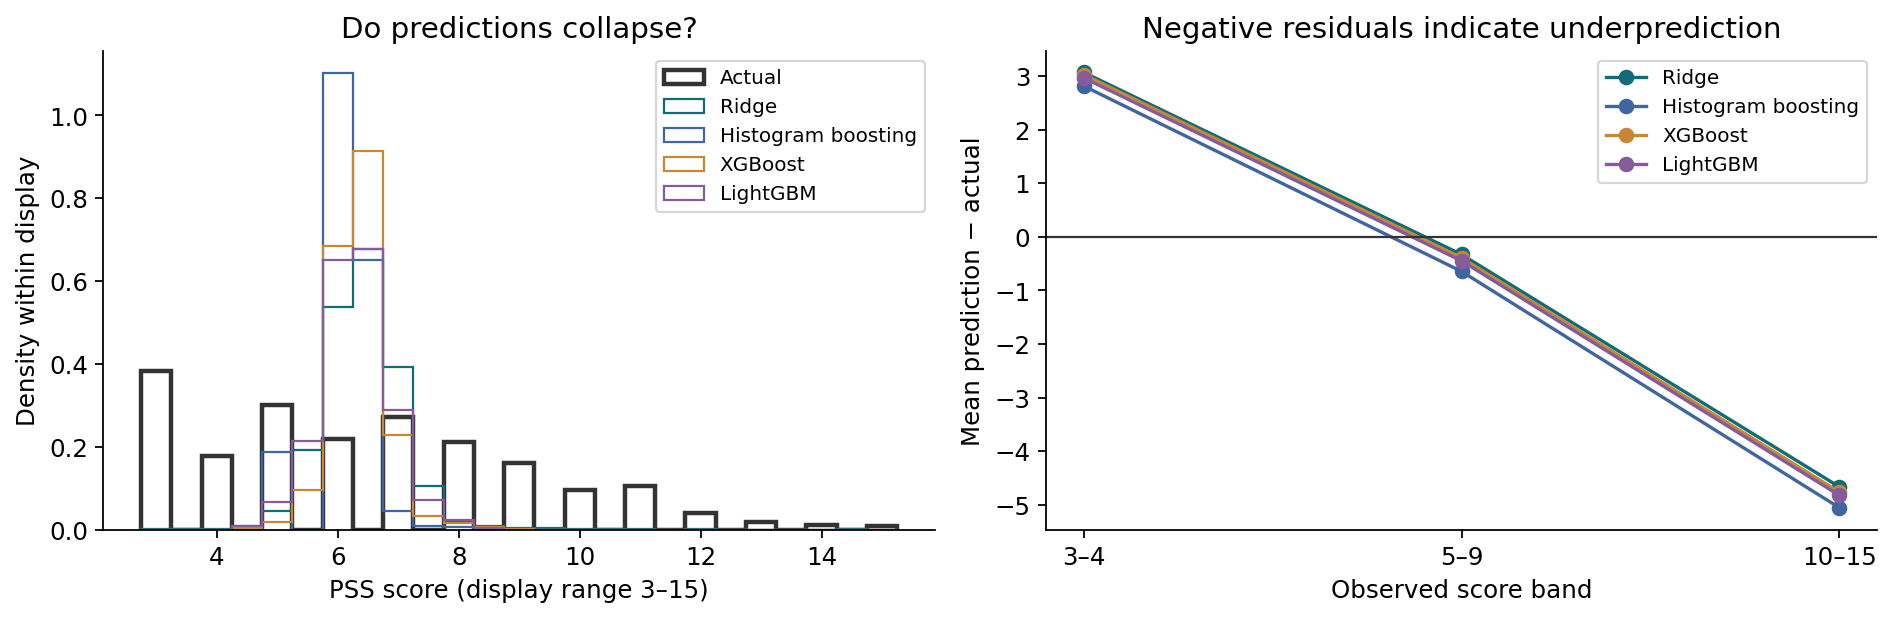

,family,stratum,responses,mae,signed_error,prediction_mean,actual_mean
54,elastic,10–15,515,4.753785,-4.753785,6.401555,11.155340
55,elastic,3–4,1033,3.096753,3.096753,6.414274,3.317522
56,elastic,5–9,2141,1.229870,-0.352670,6.402585,6.755255
60,hgb,10–15,515,5.057662,-5.057662,6.097678,11.155340
61,hgb,3–4,1033,2.812893,2.812893,6.130415,3.317522
62,hgb,5–9,2141,1.312451,-0.647316,6.107939,6.755255
66,huber,10–15,515,4.768586,-4.757075,6.398265,11.155340
67,huber,3–4,1033,2.970857,2.970270,6.287791,3.317522
68,huber,5–9,2141,1.406571,-0.415420,6.339835,6.755255
72,lasso,10–15,515,4.748520,-4.748520,6.406819,11.155340


In [6]:
figure('04_actual_predicted.png')
figure('05_predictions_residuals.png')
s=pd.DataFrame(load('strata'));display(s[s.cohort.eq('all_valid') & s['view'].eq('full') & s.dimension.eq('score_band')][['family','stratum','responses','mae','signed_error','prediction_mean','actual_mean']])

## 6 · Selection, time windows, and recording controls

Missingness and quality are distinct from physiological values. Selection stability is descriptive; correlated predictors can substitute. Point minima do not establish an optimal window.

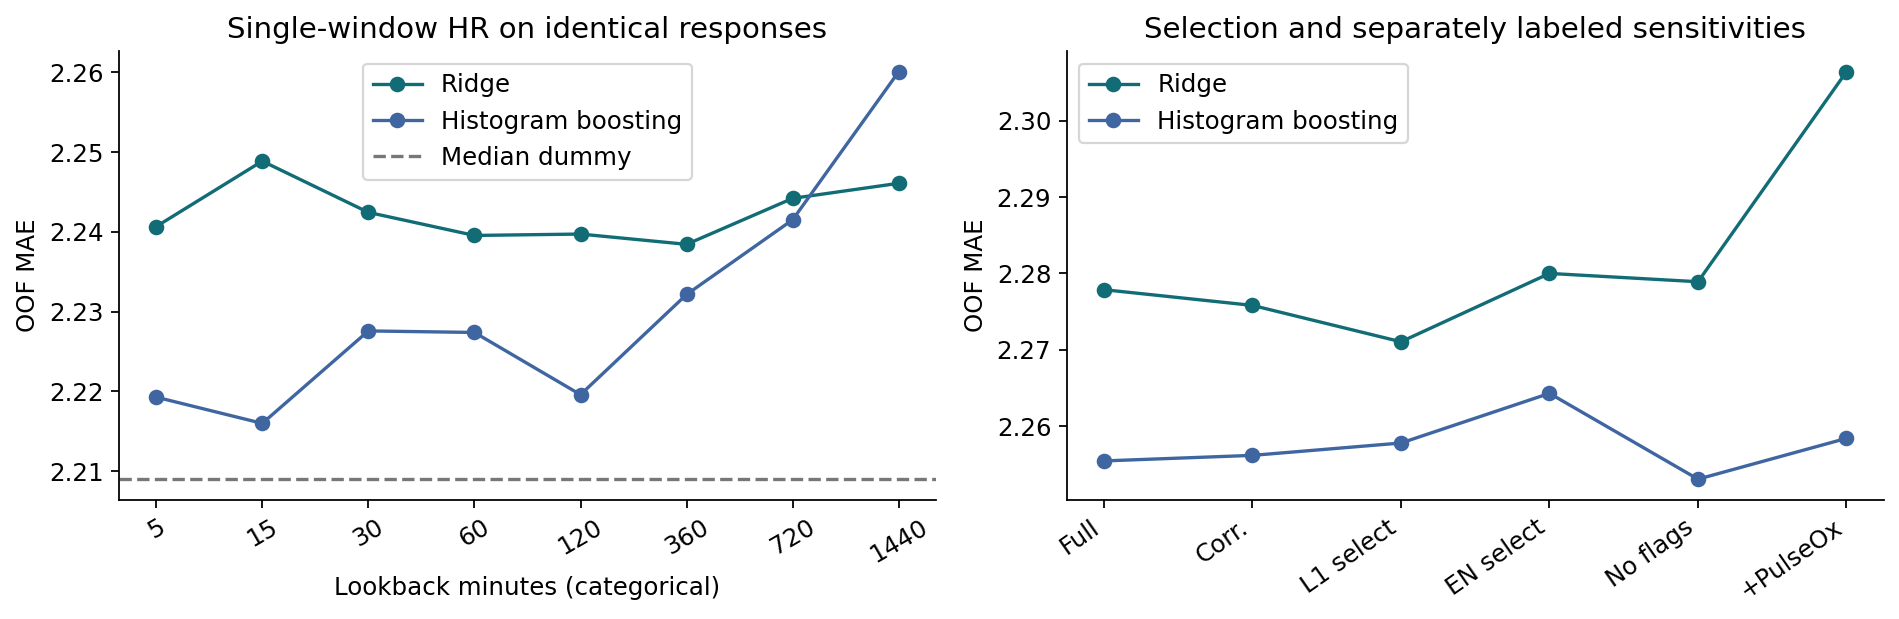

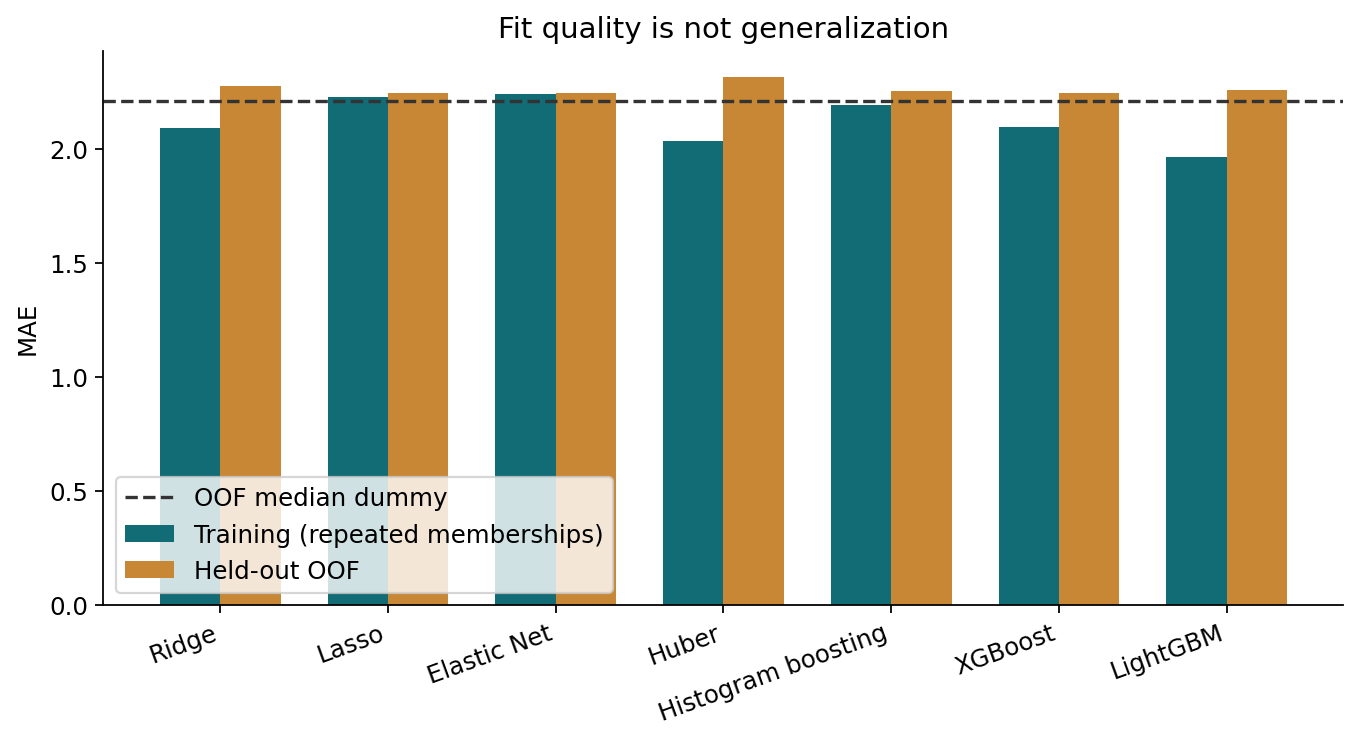

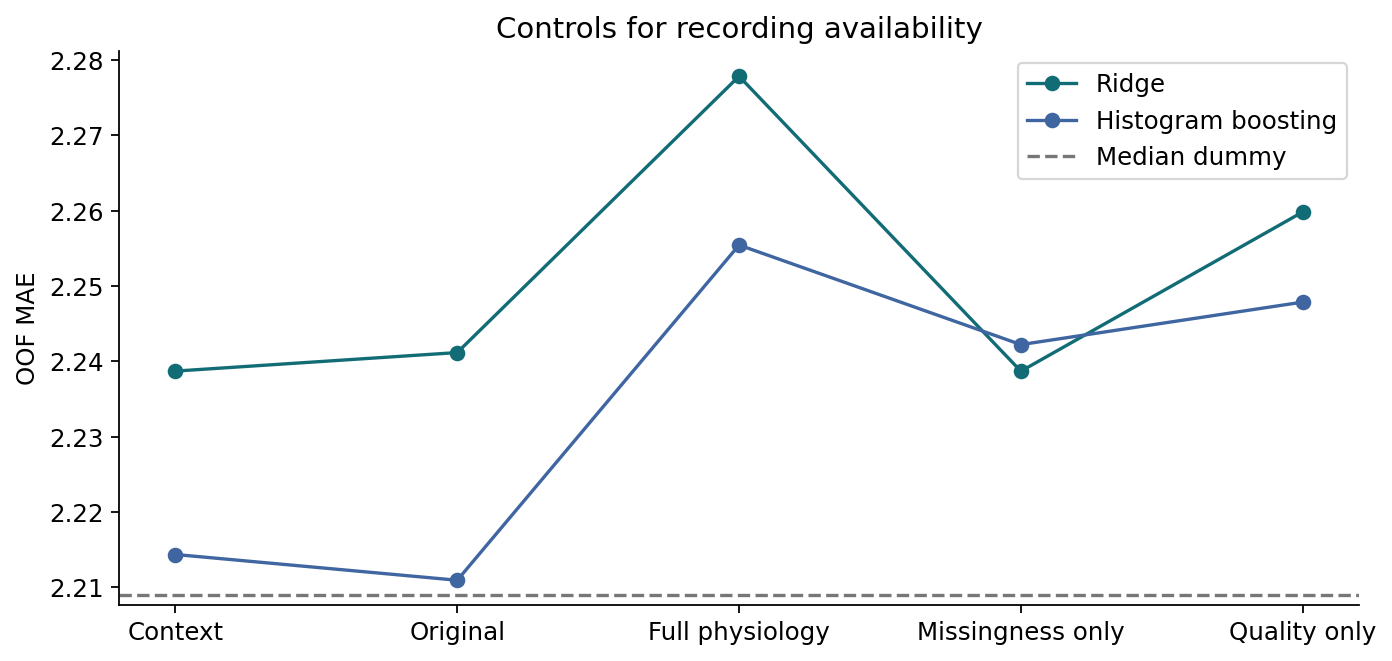

In [7]:
figure('06_windows_selection.png')
figure('07_train_oof.png')
figure('08_controls.png')

## 7 · Compare with older regressions fairly

Exact fixed-Ridge replays verify linkage and preprocessing against Notebook 05 and 09. Complete-case refits and restricted validation of larger-training-cohort models are reported separately. Never compare their headline metrics across unequal evaluation rows.

In [8]:
table('legacy_replay')
display(f[f.cohort.eq('complete60')][['view','family','responses','participants','mae','rmse','r2']])
table('restricted_evaluation')

,max_error,notebook,responses,view
0,2.664535e-15,05,1355,context
1,2.486900e-14,05,1355,original60
2,2.664535e-15,09,1355,context
3,2.486900e-14,09,1355,original60


,view,family,responses,participants,mae,rmse,r2
92,context,fixed_ridge,1355,113,2.102763,2.547822,-0.004349
93,context,hgb,1355,113,2.083181,2.564136,-0.017252
94,context,ridge,1355,113,2.102264,2.546551,-0.003347
95,context,dummy_mean,1355,113,2.101639,2.544758,-0.001935
96,context,dummy_median,1355,113,2.061255,2.556375,-0.011104
97,full,hgb,1355,113,2.090809,2.608913,-0.053091
98,full,ridge,1355,113,2.152341,2.636772,-0.075701
99,original60,fixed_ridge,1355,113,2.111658,2.557376,-0.011896
100,original60,hgb,1355,113,2.069828,2.581303,-0.030919
101,original60,ridge,1355,113,2.104098,2.548750,-0.005081


,evaluation,folds,mae,mae_high,mae_low,model,near_median_fraction,outside_target_range,participant_mae,participant_mae_high,...,prediction_sd,r2,r2_high,r2_low,responses,rmse,rmse_high,rmse_low,signed_error,spearman
0,complete60_only_training_all_valid,5,2.112640,2.264423,1.965552,all_valid__context__elastic,0.064207,0.000000,2.219004,2.382941,...,0.119931,-0.004394,0.001923,-0.036025,1355,2.547879,2.707597,2.391859,0.100339,-0.023244
1,complete60_only_training_all_valid,5,2.062157,2.226670,1.906191,all_valid__context__hgb,0.985978,0.000000,2.169084,2.350829,...,0.108707,-0.010778,0.002104,-0.055902,1355,2.555964,2.735848,2.374221,-0.253232,0.025280
2,complete60_only_training_all_valid,5,2.081418,2.241945,1.928452,all_valid__context__huber,0.864207,0.000000,2.194915,2.364886,...,0.158400,-0.007977,0.002962,-0.045439,1355,2.552419,2.726918,2.375869,-0.154750,-0.015466
3,complete60_only_training_all_valid,5,2.113269,2.265201,1.966715,all_valid__context__lasso,0.064945,0.000000,2.219511,2.383540,...,0.113961,-0.004513,0.001740,-0.036521,1355,2.548030,2.707883,2.391998,0.102392,-0.028050
4,complete60_only_training_all_valid,5,2.127213,2.278692,1.981900,all_valid__context__lgbm,0.501107,0.000000,2.235652,2.403684,...,0.326758,-0.025568,-0.005394,-0.062166,1355,2.574595,2.743661,2.412022,-0.003627,-0.055640
5,complete60_only_training_all_valid,5,2.111928,2.263912,1.964723,all_valid__context__ridge,0.118081,0.000000,2.218471,2.382882,...,0.128513,-0.004245,0.002002,-0.036046,1355,2.547690,2.707713,2.392322,0.098196,-0.018287
6,complete60_only_training_all_valid,5,2.078928,2.245020,1.922253,all_valid__context__xgb,0.904797,0.000000,2.187270,2.364955,...,0.229947,-0.021974,-0.008155,-0.064446,1355,2.570079,2.750791,2.390148,-0.240385,-0.074038
7,complete60_only_training_all_valid,5,2.118794,2.269758,1.972368,all_valid__dummy_mean,0.000000,0.000000,2.223955,2.387543,...,0.054613,-0.004586,0.001465,-0.040693,1355,2.548122,2.705957,2.393944,0.135217,-0.025459
8,complete60_only_training_all_valid,5,2.061255,2.227944,1.904213,all_valid__dummy_median,1.000000,0.000000,2.170679,2.352043,...,0.000000,-0.011104,-0.000026,-0.057516,1355,2.556375,2.737445,2.371853,-0.267897,NaN
9,complete60_only_training_all_valid,5,2.118794,2.269758,1.972368,all_valid__full__elastic,0.000000,0.000000,2.223955,2.387543,...,0.054613,-0.004586,0.001465,-0.040693,1355,2.548122,2.705957,2.393944,0.135217,-0.025459


## 8 · Findings and limitations

The lowest point MAE among the prespecified full-feature models is Elastic Net at 2.245, compared with 2.209 for the matching median dummy. Its paired MAE difference from the median is +0.036 (95% interval -0.009 to +0.080); versus its matching context model, +0.006 (+0.001 to +0.010). RMSE is 2.700, R² -0.004, and Spearman correlation -0.095. For actual scores 10–15, MAE is 4.754 and mean prediction−actual is -4.754.

These comparisons do not establish a reliable improvement over both the matching median and context baselines. Point minima are descriptive, not a new selected model or final-test result. Repeated development exploration remains a limitation.

Sparse or stale readings and survey recall mismatch remain possible limitations. These results cannot identify the cause without new measurement evidence. Participant-bootstrap intervals condition on fixed OOF predictions, repeated exploration and prespecified grids.

In [9]:
display(Markdown((ROOT/'reports/comprehensive_regression/summary.md').read_text()))
if (REPORT/'verification.json').exists(): display(pd.Series(load('verification'),name='verification').to_frame())

# Comprehensive continuous PSS regression — summary for Will

The lowest point MAE among the prespecified full-feature models is Elastic Net at 2.245, compared with 2.209 for the matching median dummy. Its paired MAE difference from the median is +0.036 (95% interval -0.009 to +0.080); versus its matching context model, +0.006 (+0.001 to +0.010). RMSE is 2.700, R² -0.004, and Spearman correlation -0.095. For actual scores 10–15, MAE is 4.754 and mean prediction−actual is -4.754.

These comparisons do not establish a reliable improvement over both the matching median and context baselines. Point minima are descriptive, not a new selected model or final-test result. Repeated development exploration remains a limitation.

Elastic Net selects zero coefficients in every full-feature outer fold and reproduces the matching training-mean dummy. Its small pooled prediction variation comes only from different training-fold means; it has no within-fold physiological discrimination. The median dummy predicts 6 throughout and has undefined Spearman correlation, not zero correlation.

| Model | MAE | 95% low | 95% high | RMSE | R² | Spearman | Participant MAE | Prediction SD |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Median dummy | 2.209 | 2.073 | 2.345 | 2.726 | -0.023 | nan | 2.222 | 0.000 |
| Mean dummy | 2.245 | 2.116 | 2.368 | 2.700 | -0.004 | -0.095 | 2.258 | 0.056 |
| Ridge | 2.278 | 2.156 | 2.400 | 2.774 | -0.059 | 0.023 | 2.291 | 0.761 |
| Lasso | 2.247 | 2.120 | 2.374 | 2.704 | -0.006 | -0.072 | 2.260 | 0.220 |
| Elastic Net | 2.245 | 2.116 | 2.368 | 2.700 | -0.004 | -0.095 | 2.258 | 0.056 |
| Huber | 2.314 | 2.188 | 2.440 | 2.873 | -0.136 | 0.019 | 2.326 | 1.072 |
| Histogram boosting | 2.255 | 2.119 | 2.393 | 2.760 | -0.048 | -0.053 | 2.269 | 0.423 |
| XGBoost | 2.246 | 2.114 | 2.373 | 2.718 | -0.017 | 0.001 | 2.259 | 0.441 |
| LightGBM | 2.260 | 2.131 | 2.390 | 2.742 | -0.035 | 0.012 | 2.274 | 0.568 |

| question | answer |
| --- | --- |
| Do expanded features improve continuous prediction? | No full-feature model has a lower point MAE than the median dummy (2.209). Even the lowest learned main comparison, Original HR4 + steps · 60m / Histogram boosting, has MAE 2.211. |
| Do physiological values add beyond context? | 0 of seven full-versus-context paired intervals supports lower MAE. The matched full models often worsen error; the quality/missingness controls do not establish a physiological signal. |
| Do selection or longer windows solve this? | The lowest selected-feature point MAE is 2.244, still above the median baseline. Single-window and multiwindow results do not justify an optimal scale. PulseOx stays provisional and does not rescue the full benchmark. |
| Do nonlinear models outperform Ridge? | Full XGBoost minus full Ridge MAE is -0.032 (95% interval -0.063 to -0.001). That modest conditional advantage does not beat the matching median/context baseline. The compared losses also differ; this is not isolated evidence for nonlinearity. |
| Can the models identify higher continuous scores? | For the 515 responses scoring 10–15, actual mean PSS is 11.16. Full-model mean predictions are about 6.1–6.5, with MAE about 4.7–5.1. Higher-score underprediction remains severe. |
| Is the problem implementation, sparsity or weak physiology? | Synthetic controls, exact legacy replays and estimator replays passed. This rules out the tested computational errors, not all possible errors. Sparse/stale readings, recall mismatch and source semantics remain plausible limitations; this benchmark cannot identify their causal contribution. |

All main models use the same 3,689 valid-score/context responses from 125 participants. All 3,706 EMA rows are retained in accounting. These are newly tuned regressions, not conversions of classification probabilities.

438 supported summaries are reused; provisional PulseOx stays separate. Eight main blocks, seven model families and prespecified secondary checks produce 98 comparisons across five frozen outer folds. Every transform/selector and hyperparameter decision stays inside grouped training splits. MAE is the selection objective; boosting losses are explicitly compared.

The full tables report all feature groups, score-band errors, calibration of continuous predictions, prediction spread, convergence, missingness/quality controls and matched legacy comparisons. Point minima do not identify an optimal window, model or physiological mechanism. High-score residuals and weak correlation must not be hidden by pooled MAE.

Intervals condition on fixed development predictions and omit retuning uncertainty and multiple-comparison correction. Timing, recall alignment, source quality, sparse observations and participant heterogeneity remain unresolved. No new HRV or proprietary Garmin stress is included.

Next: resolve measurement timing/quality and prompt/recall boundaries, then specify a narrow confirmation of any supported matched effect. Do not automatically expand the search or open the final test. See verification.md and README.md for checks and exact output paths.


,verification
estimator_replays,490
failed_jobs,0
feature_bundle,verified unchanged
final_test_evaluated,False
frozen_assignments,verified unchanged
independent_fresh_fits,14
inner_membership_checks,1470
intentional_existing_change,Notebook 14 aggregate-output privacy authoriza...
legacy_fixed_ridge_replays,4
legacy_max_prediction_error,0.0
